Ch 8.3.1 - 8.3.2

In [2]:
library(tree)
library(ISLR)
library(MASS)

In [3]:
carseats <- Carseats
carseats$High <- factor(ifelse(carseats$Sales > 8, "Yes", "No"))

In [4]:
table(carseats$High)


 No Yes 
236 164 

In [5]:
fit_full <- tree(High ~ . - Sales, data = carseats)
summary(fit_full)


Classification tree:
tree(formula = High ~ . - Sales, data = carseats)
Variables actually used in tree construction:
[1] "ShelveLoc"   "Price"       "Income"      "CompPrice"   "Population" 
[6] "Advertising" "Age"         "US"         
Number of terminal nodes:  27 
Residual mean deviance:  0.4575 = 170.7 / 373 
Misclassification error rate: 0.09 = 36 / 400 

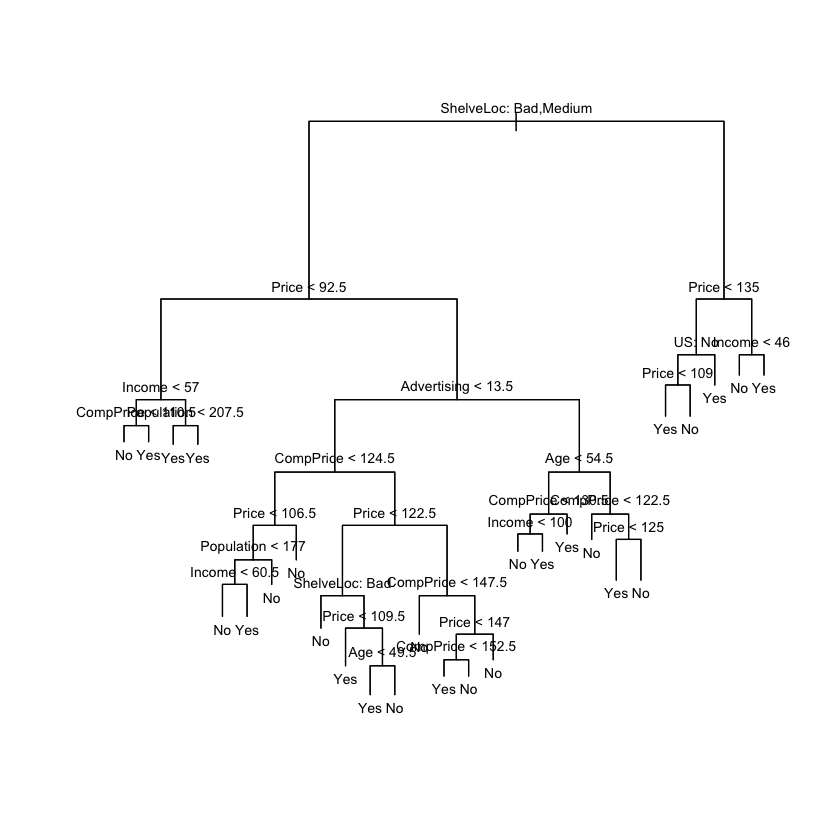

In [6]:
plot(fit_full)
text(fit_full, pretty = 0, cex = 0.7)

In [7]:
fit_full

node), split, n, deviance, yval, (yprob)
      * denotes terminal node

  1) root 400 541.500 No ( 0.59000 0.41000 )  
    2) ShelveLoc: Bad,Medium 315 390.600 No ( 0.68889 0.31111 )  
      4) Price < 92.5 46  56.530 Yes ( 0.30435 0.69565 )  
        8) Income < 57 10  12.220 No ( 0.70000 0.30000 )  
         16) CompPrice < 110.5 5   0.000 No ( 1.00000 0.00000 ) *
         17) CompPrice > 110.5 5   6.730 Yes ( 0.40000 0.60000 ) *
        9) Income > 57 36  35.470 Yes ( 0.19444 0.80556 )  
         18) Population < 207.5 16  21.170 Yes ( 0.37500 0.62500 ) *
         19) Population > 207.5 20   7.941 Yes ( 0.05000 0.95000 ) *
      5) Price > 92.5 269 299.800 No ( 0.75465 0.24535 )  
       10) Advertising < 13.5 224 213.200 No ( 0.81696 0.18304 )  
         20) CompPrice < 124.5 96  44.890 No ( 0.93750 0.06250 )  
           40) Price < 106.5 38  33.150 No ( 0.84211 0.15789 )  
             80) Population < 177 12  16.300 No ( 0.58333 0.41667 )  
              160) Income < 60.5 6   0

In [8]:
set.seed(2)
n         <- nrow(carseats)
train_idx <- sample(n, 200)
test_dat  <- carseats[-train_idx, ]

In [9]:
fit_train <- tree(High ~ . - Sales, data = carseats, subset = train_idx)
pred_test <- predict(fit_train, newdata = test_dat, type = "class")

In [10]:
table(predicted = pred_test, actual = test_dat$High)
mean(pred_test == test_dat$High)

         actual
predicted  No Yes
      No  104  33
      Yes  13  50

[1] 0.77

In [11]:
set.seed(3)
cv_class <- cv.tree(fit_train, FUN = prune.misclass)
names(cv_class)
cv_class

[1] "size"   "dev"    "k"      "method"

$size
[1] 21 19 14  9  8  5  3  2  1

$dev
[1] 74 76 81 81 75 77 78 85 81

$k
[1] -Inf  0.0  1.0  1.4  2.0  3.0  4.0  9.0 18.0

$method
[1] "misclass"

attr(,"class")
[1] "prune"         "tree.sequence"

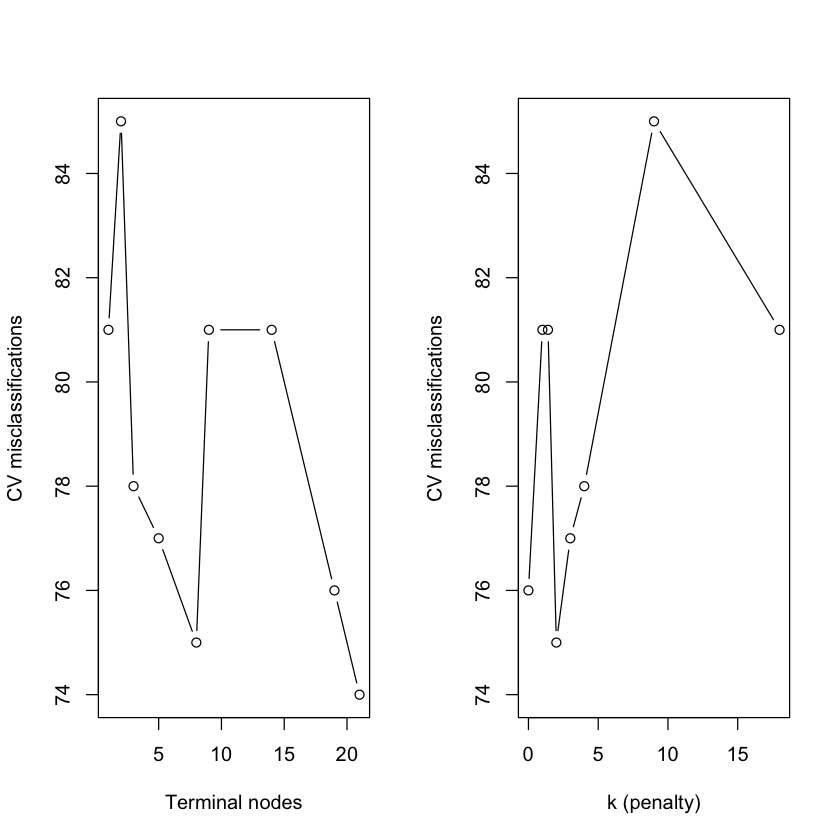

In [12]:
par(mfrow = c(1, 2))
plot(cv_class$size, cv_class$dev, type = "b",
     xlab = "Terminal nodes", ylab = "CV misclassifications")
plot(cv_class$k, cv_class$dev, type = "b",
     xlab = "k (penalty)", ylab = "CV misclassifications")
par(mfrow = c(1, 1))

In [13]:
best_size <- cv_class$size[which.min(cv_class$dev)]
best_size

[1] 21

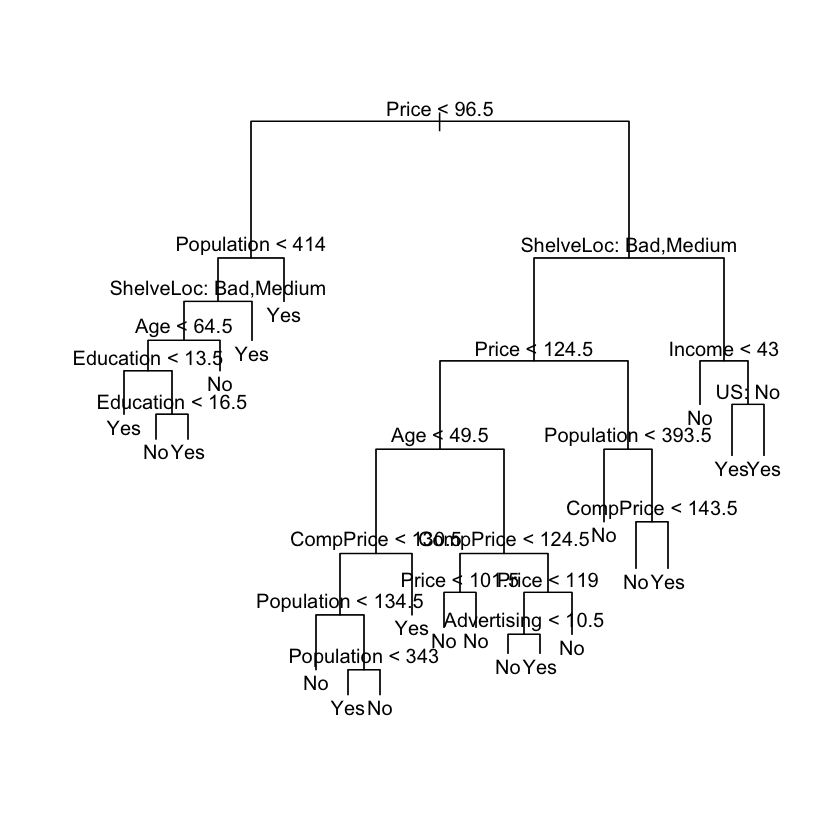

In [14]:
fit_pruned <- prune.misclass(fit_train, best = best_size)
plot(fit_pruned)
text(fit_pruned, pretty = 0)

In [15]:
pred_pruned <- predict(fit_pruned, newdata = test_dat, type = "class")
table(predicted = pred_pruned, actual = test_dat$High)
mean(pred_pruned == test_dat$High)

         actual
predicted  No Yes
      No  104  32
      Yes  13  51

[1] 0.775

In [16]:
fit_big  <- prune.misclass(fit_train, best = 15)
pred_big <- predict(fit_big, newdata = test_dat, type = "class")
mean(pred_big == test_dat$High)

[1] 0.775

In [17]:
set.seed(1)
bos_train <- sample(nrow(Boston), nrow(Boston) / 2)
bos_test  <- Boston[-bos_train, ]

In [18]:
reg_fit <- tree(medv ~ ., data = Boston, subset = bos_train)
summary(reg_fit)


Regression tree:
tree(formula = medv ~ ., data = Boston, subset = bos_train)
Variables actually used in tree construction:
[1] "rm"    "lstat" "crim"  "age"  
Number of terminal nodes:  7 
Residual mean deviance:  10.38 = 2555 / 246 
Distribution of residuals:
    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-10.1800  -1.7770  -0.1775   0.0000   1.9230  16.5800 

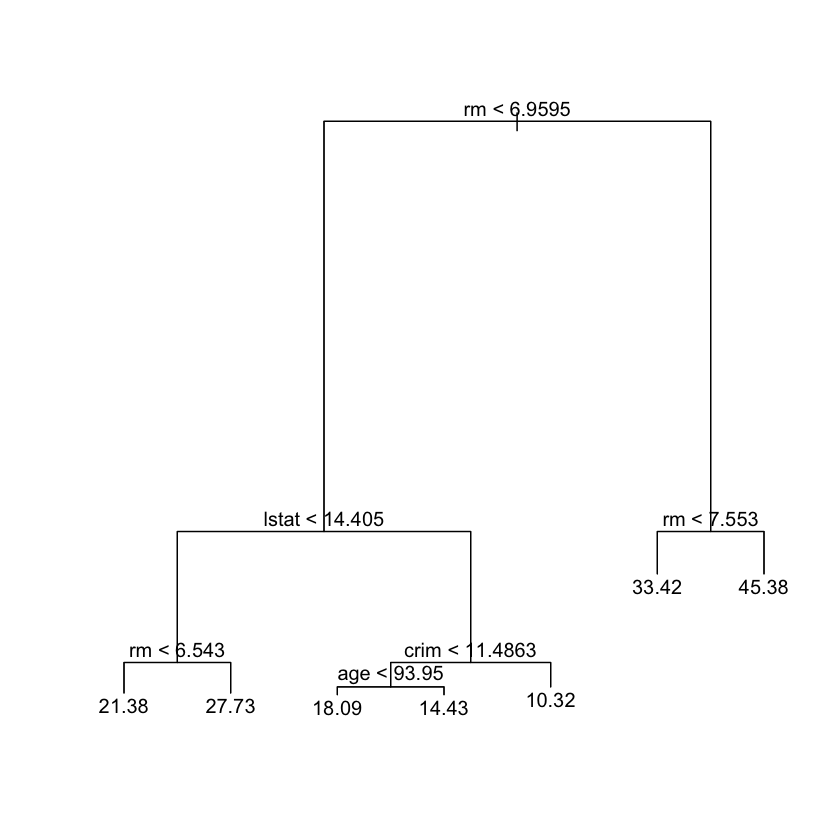

In [19]:
plot(reg_fit)
text(reg_fit, pretty = 0)

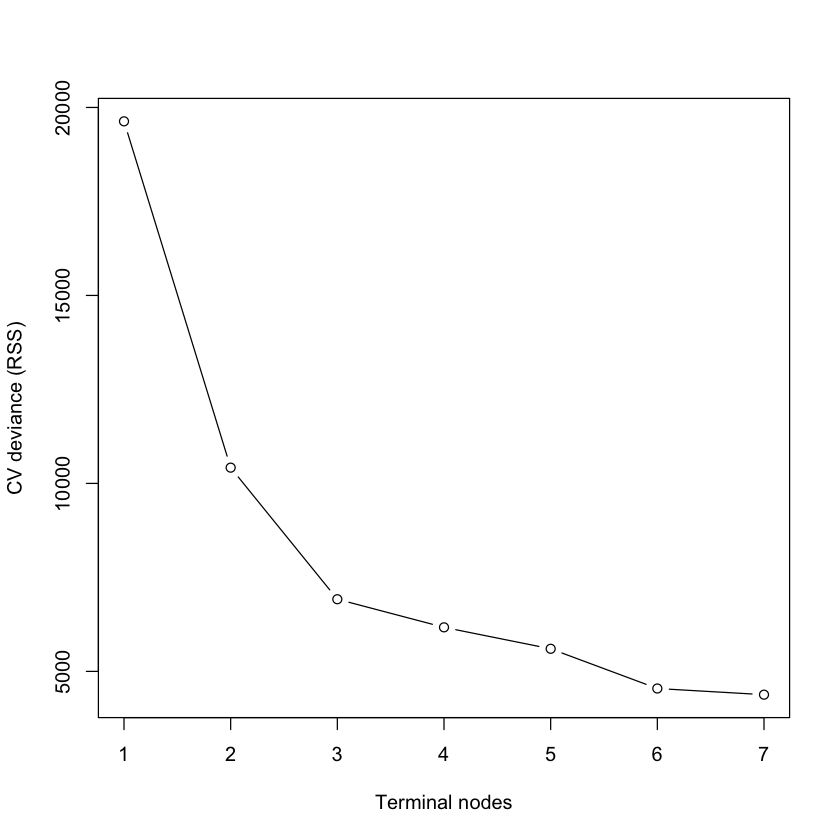

In [20]:
reg_cv <- cv.tree(reg_fit)
plot(reg_cv$size, reg_cv$dev, type = "b",
     xlab = "Terminal nodes", ylab = "CV deviance (RSS)")

In [21]:
reg_best <- reg_cv$size[which.min(reg_cv$dev)]
reg_best

[1] 7

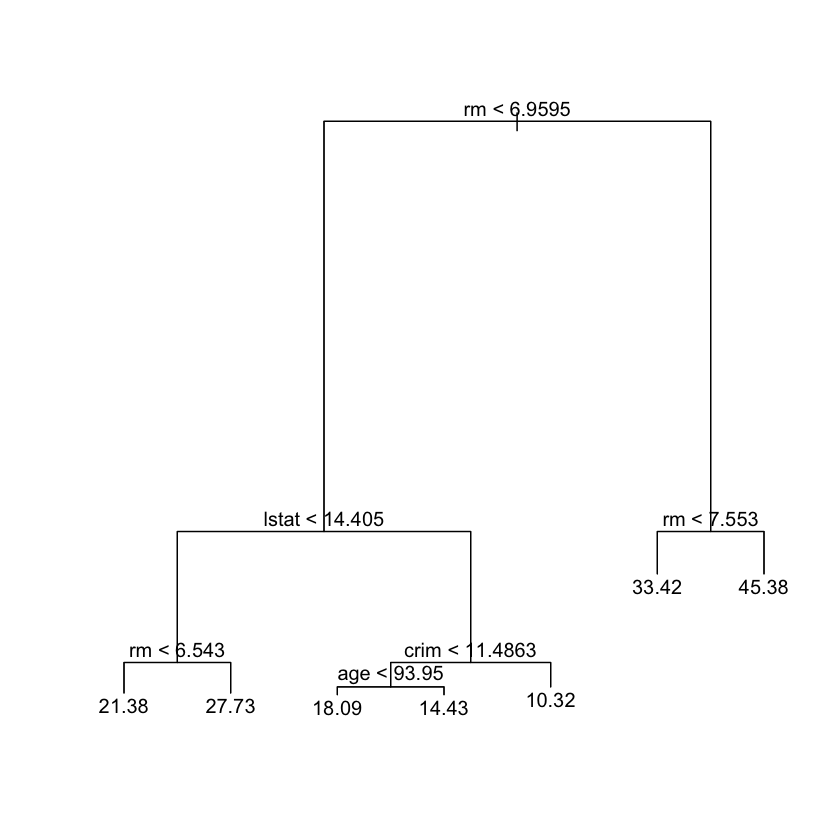

In [22]:
reg_pruned <- prune.tree(reg_fit, best = reg_best)
plot(reg_pruned)
text(reg_pruned, pretty = 0)
# If CV picks the full tree, try best = 5 for a shallower one.

In [23]:
mse <- function(pred, y) mean((pred - y)^2)

pred_full  <- predict(reg_fit,    newdata = bos_test)
pred_prune <- predict(reg_pruned, newdata = bos_test)

In [24]:
mse(pred_full,  bos_test$medv)
mse(pred_prune, bos_test$medv)

[1] 35.28688

[1] 35.28688

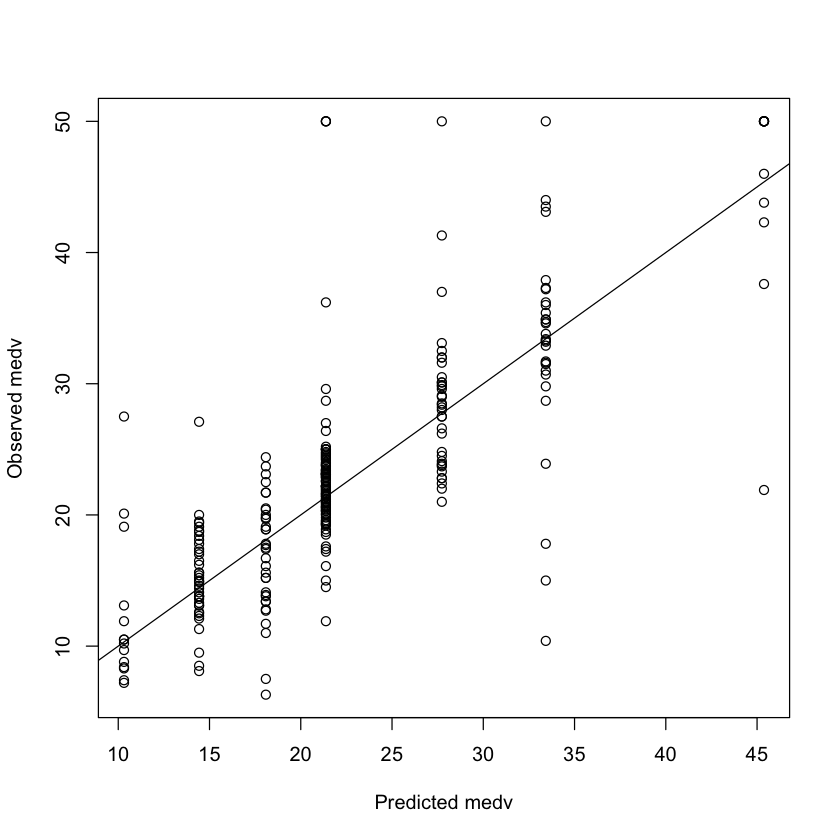

In [25]:
plot(pred_full, bos_test$medv,
     xlab = "Predicted medv", ylab = "Observed medv")
abline(0, 1)